# Modélisation : TF-IDF, transfert et identification de langue

Les modèles sont déjà entraînés (`models/`). Ce carnet relit les métriques, les matrices et quelques erreurs.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
PROC = ROOT / "data" / "processed"
RAW = ROOT / "data" / "raw"
FIG = ROOT / "reports" / "figures"
REP = ROOT / "reports"

table = pd.read_csv(REP / "metrics_table.csv")
key = json.loads((REP / "key_figures.json").read_text())
display(table.round(3))


,modele,jeu,f1_macro,accuracy
0,TF-IDF fr,fr_test,0.912,0.912
1,TF-IDF fr,fon_proj_test,0.378,0.427
2,TF-IDF fr,fon_verifie,0.398,0.500
3,TF-IDF fr,fr_val,0.915,0.916
4,TF-IDF fr+fon,fr_test,0.916,0.916
5,TF-IDF fr+fon,fon_proj_test,0.816,0.827
6,TF-IDF fr+fon,fon_verifie,0.807,0.809
7,TF-IDF fr+fon,fr_val,0.911,0.912


## Comparaison des F1 macro

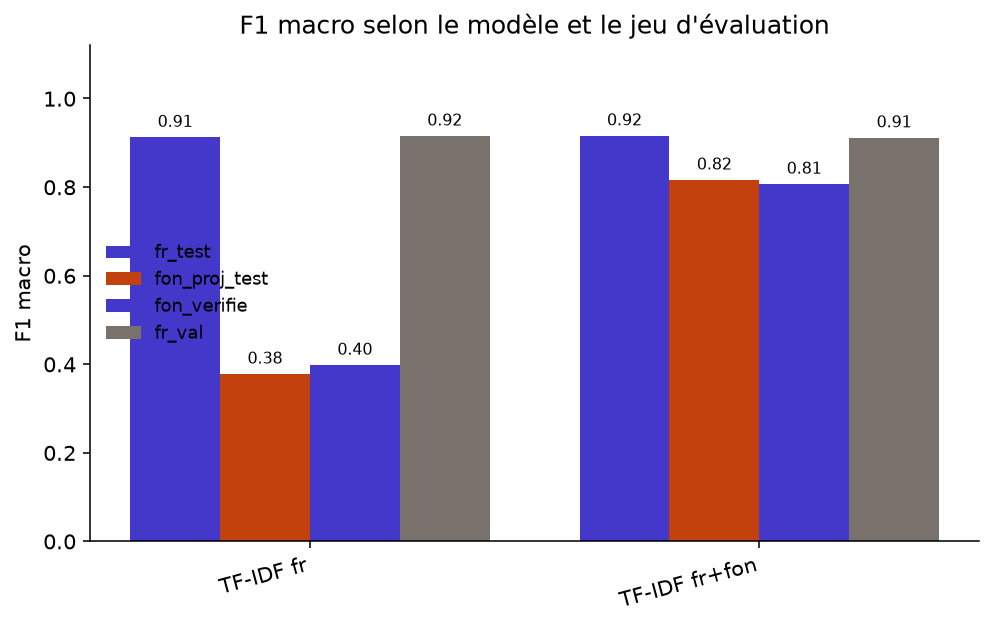

In [2]:
display(Image(str(FIG / "04_comparaison_f1.png")))

## Matrices du modèle mixte (français + fongbé projeté)

De gauche à droite : test Allociné, test fongbé projeté, jeu fongbé relu.

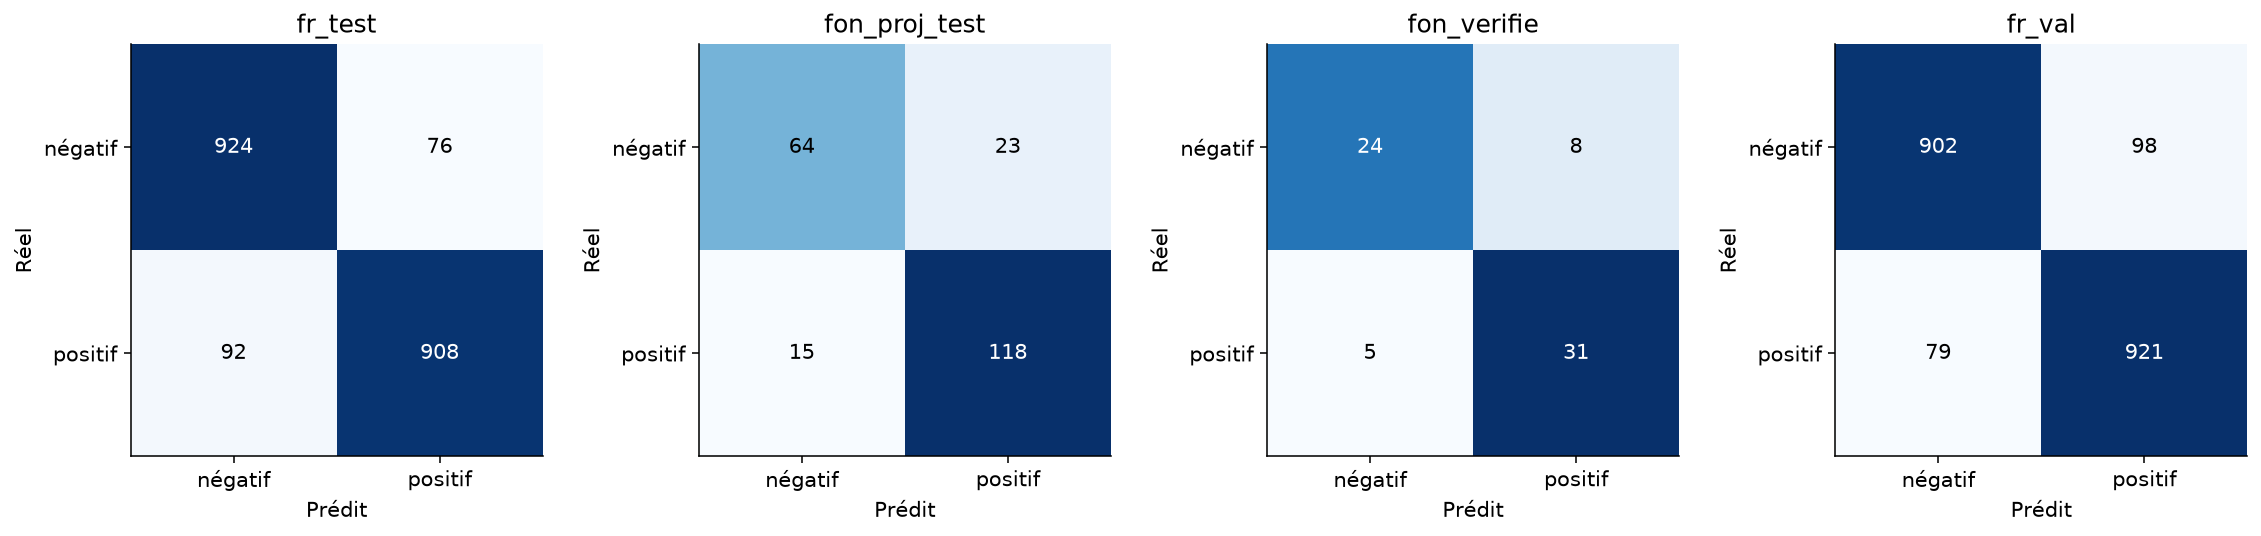

In [3]:
display(Image(str(FIG / "03_matrices.png")))

## N-grammes distinctifs

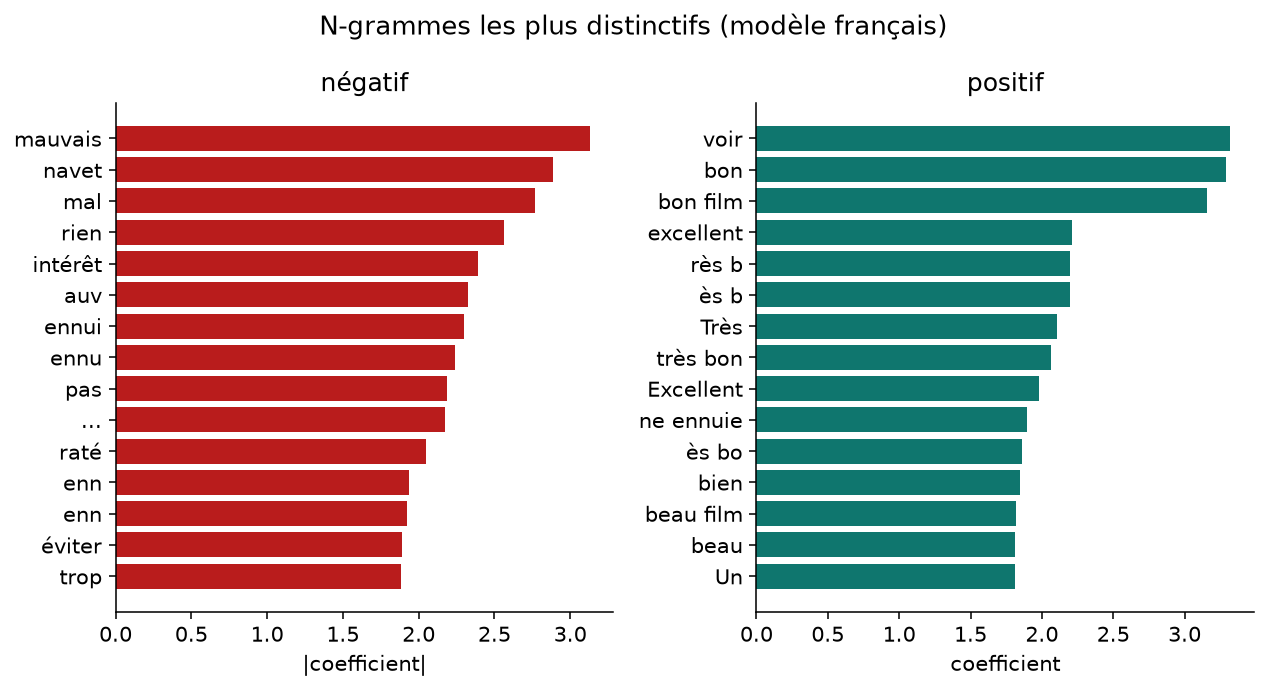

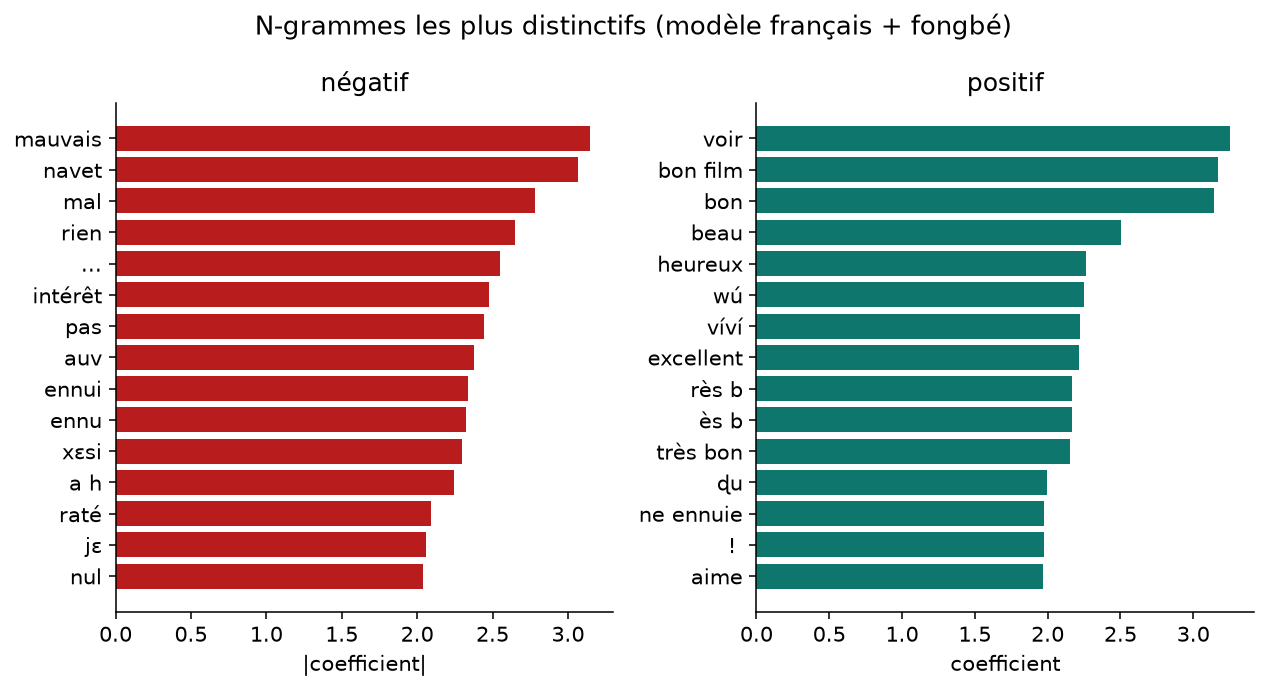

In [4]:
display(Image(str(FIG / "05_coefficients_fr.png")))
display(Image(str(FIG / "06_coefficients_mix.png")))


## Erreurs sur le jeu fongbé relu

In [5]:
err = pd.read_csv(REP / "erreurs_TF-IDF_fr+fon_fon_verifie.csv")
print(len(err), "erreurs")
cols = [c for c in ["texte_fr", "texte", "label", "predit"] if c in err.columns]
display(err[cols].head(10))


13 erreurs


,texte_fr,texte,label,predit
0,j'ai peur de la mort,un ɖì kú xɛsì,0,1
1,et ils sentent la douleur,bɔ e nɔ se wuvɛ enɛ ɔ,0,1
2,"Un individu mordu par un serpent, prend peur à...",Dan ɖu we nu a mɔ vɔn ɔ a na si.,0,1
3,tu es heureux d'avoir un bon fils,a ɖù vĭ gbɛ̀,1,0
4,Ah ! Que c’est beau !,Ablé lɔ̆nlɔ̆n !,1,0
5,il s'est dégagé avec succès de l'affaire,é gló nŭ,1,0
6,vive la joie dieu existe,wásí wásí óó aluwáásí o owó owó măwù wɛ́ tíin,1,0
7,mentir en attribuant ce mensonge à un autre,ɖŏ nùvú dŏ mε nu,0,1
8,le chien saute de joie,cuku lɔn awajijɛ tɔn,1,0
9,il l'a complètement abandonné,e jó é dó bĭ,0,1


## Identification de langue

In [6]:
lid = key["lid"]
print("exactitude", round(lid["accuracy"], 3), "F1 macro", round(lid["f1_macro"], 3), "n =", lid["n"])
print("Score élevé attendu : l'orthographe du fongbé est très distinctive.")


exactitude 0.998 F1 macro 0.997 n = 6700
Score élevé attendu : l'orthographe du fongbé est très distinctive.
